In [1]:
!git clone https://github.com/WongKinYiu/yolov7.git



Cloning into 'yolov7'...
remote: Enumerating objects: 1197, done.
remote: Total 1197 (delta 0), reused 0 (delta 0), pack-reused 1197 (from 1)
Receiving objects: 100% (1197/1197), 74.29 MiB | 22.88 MiB/s, done.
Resolving deltas: 100% (511/511), done.


In [2]:
%cd /content/yolov7

!python --version
!nvidia-smi

import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


/content/yolov7
Python 3.13.16
Tue Nov 10 13:25:37 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   58C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+----------------

In [3]:

import numpy
import cv2
import torchvision
import yaml

print("NumPy:", numpy.__version__)
print("OpenCV:", cv2.__version__)
print("Torchvision:", torchvision.__version__)
print("PyYAML:", yaml.__version__)


NumPy: 2.4.6
OpenCV: 4.14.0
Torchvision: 0.29.1+cu130
PyYAML: 6.0.3


In [5]:
%cd /content/yolov7

!pip install seaborn thop



/content/yolov7


In [6]:
import torch
import numpy
import cv2

print("Python environment ready")
print("NumPy:", numpy.__version__)
print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.is_available())



Python environment ready
NumPy: 2.4.6
PyTorch: 2.14.1+cu130
GPU: True


In [7]:

%cd /content/yolov7

!wget -q https://github.com/WongKinYiu/yolov7/releases/download/v0.1/yolov7.pt

import os

print("Модель завантажена:", os.path.exists("yolov7.pt"))
print("Розмір файлу:", round(os.path.getsize("yolov7.pt") / 1024**2, 2), "MB")


/content/yolov7
Модель завантажена: True
Розмір файлу: 72.09 MB


In [8]:

import os

image_path = "/content/yolov7/inference/images/horses.jpg"

print("Зображення існує:", os.path.exists(image_path))


Зображення існує: True


In [10]:

%cd /content/yolov7

file_path = "models/experimental.py"

with open(file_path, "r") as f:
    code = f.read()

code = code.replace(
    "torch.load(w, map_location=map_location)",
    "torch.load(w, map_location=map_location, weights_only=False)"
)

with open(file_path, "w") as f:
    f.write(code)

print("Сумісність із новим PyTorch налаштована!")



/content/yolov7
Сумісність із новим PyTorch налаштована!


In [11]:

%cd /content/yolov7

!python detect.py --weights yolov7.pt --conf 0.25 --img-size 640 --source inference/images/horses.jpg --device 0


/content/yolov7
Namespace(weights=['yolov7.pt'], source='inference/images/horses.jpg', img_size=640, conf_thres=0.25, iou_thres=0.45, device='0', view_img=False, save_txt=False, save_conf=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project='runs/detect', name='exp', exist_ok=False, no_trace=False)
YOLOR 🚀 v0.1-128-ga207844 torch 2.14.1+cu130 CUDA:0 (Tesla T4, 14912.6875MB)

Fusing layers... 
RepConv.fuse_repvgg_block
RepConv.fuse_repvgg_block
RepConv.fuse_repvgg_block
/usr/local/lib/python3.13/dist-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/TensorShape.cpp:4221.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
Model Summary: 306 layers, 36905341 parameters, 6652669 gradients, 104.5 GFLOPS
 Convert model to Traced-model... 
/usr/local/lib/python3.13/dist-packages/to

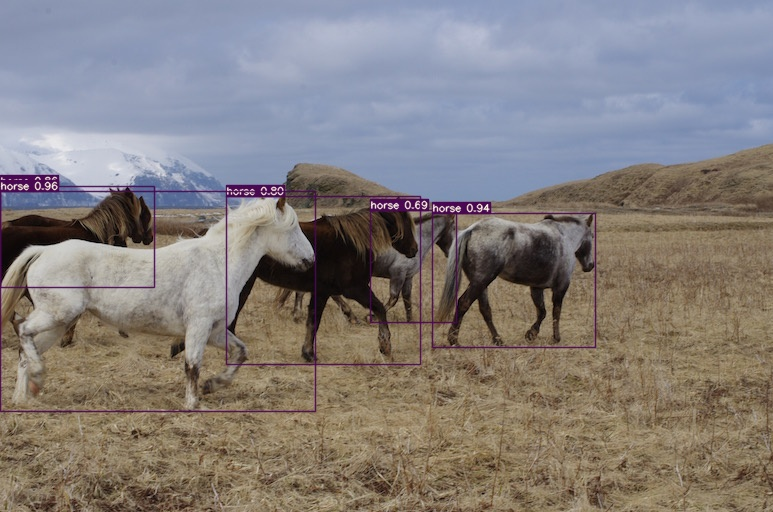

In [12]:
import glob
from IPython.display import Image, display

files = glob.glob("/content/yolov7/runs/detect/exp*/horses.jpg")

display(Image(filename=files[-1]))
